# Freight Rate Prediction Engine --> Modeling, Validation & Inference

## Exploring train-test and validation dataset (EDA)

In [1]:
# importing required libraries
%pip install pandas numpy matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
freight = pd.read_csv(r"C:\Users\Ravichandran\OneDrive\Desktop\freight-rate-ml\data\train-test.csv")
freight = freight.copy()
freight

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47995,TR-047996,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,TR-047998,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,TR-047999,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46


In [4]:
freight.columns.to_list()

['load_id',
 'pickup',
 'delivery',
 'pickup_lat',
 'pickup_lon',
 'delivery_lat',
 'delivery_lon',
 'distance',
 'equipment',
 'weight',
 'date',
 'market_index',
 'quote_signal',
 'posted_rate']

In [5]:
freight.info()
freight.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


In [6]:
# dataset shape rows , columns
freight.shape

(48000, 14)

In [7]:
#checking null values in dataset
freight.isnull().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [8]:
print(f"Duplicated rows : {freight.duplicated().sum()} ")

Duplicated rows : 0 


In [9]:
# checking duplicate load ID's
print("Duplicate load_id = " , freight["load_id"].duplicated().sum())

Duplicate load_id =  0


In [10]:
# checking date form
freight["date"]

0        2025-01-01
1        2025-01-01
2        2025-01-01
3        2025-01-01
4        2025-01-01
            ...    
47995    2025-10-31
47996    2025-10-31
47997    2025-10-31
47998    2025-10-31
47999    2025-10-31
Name: date, Length: 48000, dtype: object

In [11]:
#checking unique values in pickup
print(freight["pickup"].value_counts().count())
print(freight["pickup"].unique())

64
['Richmond' 'Philadelphia' 'Hartford' 'Dallas' 'Phoenix' 'Fresno'
 'San Francisco' 'Bakersfield' 'Albuquerque' 'Harrisburg' 'Mobile'
 'Nashville' 'Detroit' 'Albany' 'New Orleans' 'Reno' 'Austin'
 'Chattanooga' 'Cincinnati' 'Syracuse' 'Atlanta' 'Oklahoma City'
 'Lexington' 'Los Angeles' 'Providence' 'Madison' 'El Paso' 'Washington'
 'Amarillo' 'Green Bay' 'Memphis' 'Baton Rouge' 'Kansas City' 'Fort Wayne'
 'Charleston' 'Columbia' 'Grand Rapids' 'Jacksonville' 'Corpus Christi'
 'Birmingham' 'Milwaukee' 'Tampa' 'Raleigh' 'Indianapolis' 'Baltimore'
 'Boston' 'San Antonio' 'Montgomery' 'Buffalo' 'New York' 'Houston'
 'Dayton' 'Toledo' 'Greensboro' 'Tulsa' 'Savannah' 'Shreveport' 'Lubbock'
 'St. Louis' 'Little Rock' 'Louisville' 'Salt Lake City' 'Las Vegas'
 'Tucson']


In [12]:
#checking unique values in delivery
print(freight["delivery"].value_counts().count())
print(freight["delivery"].unique())

64
['Baltimore' 'Philadelphia' 'Green Bay' 'Atlanta' 'Nashville'
 'Corpus Christi' 'San Antonio' 'Kansas City' 'Montgomery' 'Phoenix'
 'Fresno' 'Lexington' 'El Paso' 'Syracuse' 'Louisville' 'Baton Rouge'
 'Bakersfield' 'Albuquerque' 'Cincinnati' 'Oklahoma City' 'Mobile'
 'Fort Wayne' 'Lubbock' 'New Orleans' 'Columbia' 'Hartford' 'Chattanooga'
 'New York' 'Amarillo' 'Harrisburg' 'Las Vegas' 'Salt Lake City'
 'Richmond' 'Charleston' 'Reno' 'Milwaukee' 'Jacksonville' 'Albany'
 'Indianapolis' 'Memphis' 'Dayton' 'Greensboro' 'Shreveport' 'Buffalo'
 'Grand Rapids' 'Austin' 'Houston' 'Raleigh' 'Madison' 'St. Louis' 'Tampa'
 'Boston' 'Tulsa' 'Tucson' 'Providence' 'Birmingham' 'Toledo'
 'Los Angeles' 'San Francisco' 'Little Rock' 'Detroit' 'Washington'
 'Dallas' 'Savannah']


In [13]:
#checking whether distance  contains negative values
negative_distance = (freight['distance']<0).any().sum()
print("")
print("Negative distance = ", negative_distance)


Negative distance =  0


In [14]:
# missing values inspection on "weight and market index"
print(freight[['weight' , 'market_index']].isnull().sum())
print(freight[['weight' , 'market_index']].describe())

weight          300
market_index    374
dtype: int64
             weight  market_index
count  47700.000000  47626.000000
mean   31028.844004      1.083387
std     9391.440620      0.168091
min   -47500.000000      0.676390
25%    25800.000000      0.949670
50%    31436.500000      1.055800
75%    37018.000000      1.219590
max    47500.000000      1.467780


In [15]:
# checking whether validation dataset also contains missing values in this 2 columns
valide = pd.read_csv(r'C:\Users\Ravichandran\OneDrive\Desktop\freight-rate-ml\data\validation.csv')
print(valide[['weight' , 'market_index']].isnull().sum())
print(valide[['weight' , 'market_index']].describe())

weight          165
market_index    249
dtype: int64
             weight  market_index
count  11835.000000  11751.000000
mean   30506.636248      0.926913
std    10572.590450      0.074109
min   -47500.000000      0.723610
25%    25493.000000      0.863880
50%    31193.000000      0.922900
75%    36843.500000      0.992355
max    47500.000000      1.098950


In [16]:
# In both validation and traning dataset contains the negative mean values min -47500.000000
print("Train negative weights:" , (freight['weight'] < 0).sum())
print("validation negative weights:" , (valide['weight'] < 0).sum())

Train negative weights: 292
validation negative weights: 145


In [17]:
# actual negative  values in weights
print(freight[freight['weight'] < 0]['weight'].head(10))

68     -36559.0
204    -26670.0
206    -20003.0
225    -23981.0
376    -41397.0
446    -37215.0
495    -31214.0
641    -41023.0
806    -28320.0
1093   -25153.0
Name: weight, dtype: float64


In [18]:
# Fix the nagative weight values to positive  weightusing abs() method 
# becouse values are in correct range with wrong sign in both dataset
freight['weight'] = freight['weight'].abs() 
valide['weight'] = valide['weight'].abs()

In [19]:
# filing missing values by calculating the median of weight and market_index from traning data
train_weight_median = freight['weight'].median()
train_market_median  = freight['market_index'].median()

# filling Nan's in train using above  medians 
freight['weight'] = freight['weight'].fillna(train_weight_median)
freight['market_index'] =  freight['market_index'].fillna(train_market_median)

# filling Nan's in validation using above medians
valide['weight'] = valide['weight'].fillna(train_weight_median)
valide['market_index'] = valide['market_index'].fillna(train_market_median)

In [20]:
#checking applied median
print(freight['weight'].head(10))
print(freight['market_index'].head(10))

0    30658.0
1    17555.0
2    31721.0
3    32333.0
4    35183.0
5    17018.0
6    19112.0
7    29169.0
8    35018.0
9    34671.0
Name: weight, dtype: float64
0    0.95684
1    0.97623
2    1.00971
3    0.94518
4    0.98480
5    0.95167
6    0.95696
7    0.97818
8    0.96534
9    0.98475
Name: market_index, dtype: float64


In [21]:
print("train-testdataset:\n", freight.isnull().sum())
print("Validate dataset:\n" , valide.isnull().sum())

train-testdataset:
 load_id         0
pickup          0
delivery        0
pickup_lat      0
pickup_lon      0
delivery_lat    0
delivery_lon    0
distance        0
equipment       0
weight          0
date            0
market_index    0
quote_signal    0
posted_rate     0
dtype: int64
Validate dataset:
 load_id         0
pickup          0
delivery        0
pickup_lat      0
pickup_lon      0
delivery_lat    0
delivery_lon    0
distance        0
equipment       0
weight          0
date            0
market_index    0
quote_signal    0
dtype: int64


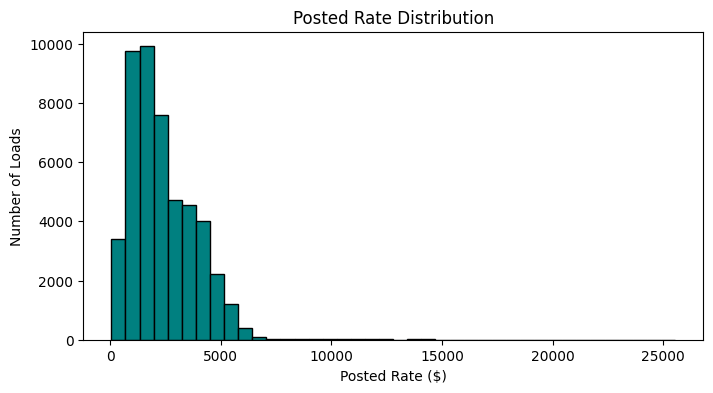

In [22]:
# cheking posted rate distribution
plt.figure(figsize=(8,4))
plt.hist(freight['posted_rate'] , bins=40 , color='teal', edgecolor='black')
plt.title("Posted Rate Distribution")
plt.xlabel("Posted Rate ($)")
plt.ylabel("Number of Loads")
plt.show()

In [23]:
#cheking the correlation between the [market index , quote signal , posted rate
print(freight[['market_index' , 'quote_signal' , 'posted_rate']].corr())

              market_index  quote_signal  posted_rate
market_index      1.000000     -0.067585     0.034022
quote_signal     -0.067585      1.000000    -0.039858
posted_rate       0.034022     -0.039858     1.000000


In [24]:
# creating temporary varible called "rate_per_mile" to check whether the quote_signal directly pushes up the price per mile
freight['rate_per_mile'] = freight['posted_rate'] / freight['distance']
print(freight[['market_index' , 'quote_signal' , 'posted_rate' , 'rate_per_mile']].corr())

               market_index  quote_signal  posted_rate  rate_per_mile
market_index       1.000000     -0.067585     0.034022       0.083360
quote_signal      -0.067585      1.000000    -0.039858       0.049342
posted_rate        0.034022     -0.039858     1.000000       0.003147
rate_per_mile      0.083360      0.049342     0.003147       1.000000


In [25]:
# seeing those correlation with posted_rate = 0. values, 
# need to check whether those have extreme outliers or zero distance in rete_per_mile and relationship is non linear
print("Distance :\n",freight['distance'].describe())
print("rate per mile :\n" , freight['rate_per_mile'].describe())
print("Distance vs posted rate :\n", freight[['distance' , 'posted_rate']].corr())

Distance :
 count    48000.000000
mean      1135.856654
std        728.564416
min         70.000000
25%        550.400000
50%        953.300000
75%       1645.525000
max       3439.800000
Name: distance, dtype: float64
rate per mile :
 count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
25%          1.986974
50%          2.145348
75%          2.342696
max         14.125294
Name: rate_per_mile, dtype: float64
Distance vs posted rate :
              distance  posted_rate
distance     1.000000     0.908519
posted_rate  0.908519     1.000000


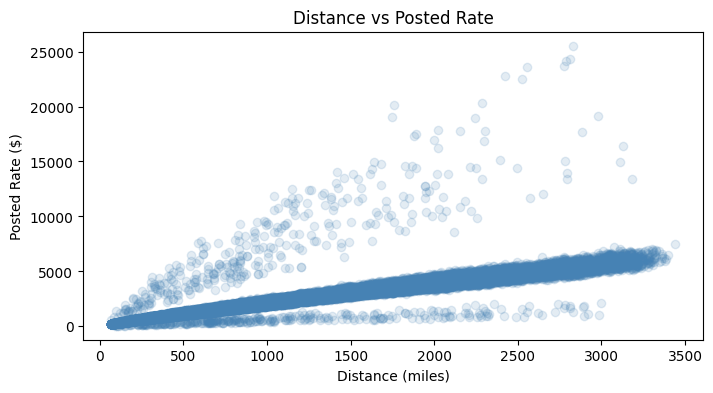

In [26]:
# distance VS posted rate
plt.figure(figsize=(8, 4))
plt.scatter(freight["distance"], freight["posted_rate"], alpha=0.15, color="steelblue")
plt.title("Distance vs Posted Rate")
plt.xlabel("Distance (miles)")
plt.ylabel("Posted Rate ($)")
plt.show()

In [27]:
# To understand quote_signal distribution to understand its range and scale 
freight['quote_signal'].describe()

count    48000.000000
mean         2.062468
std          0.291391
min          0.692280
25%          1.891030
50%          2.055750
75%          2.221685
max          3.610350
Name: quote_signal, dtype: float64

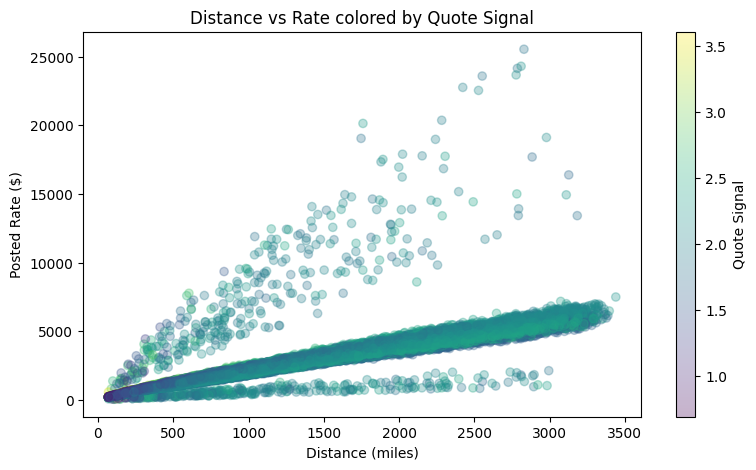

In [28]:
# checking ist for the same distance does higher quote signal means higher price 
plt.figure(figsize=(9, 5))
scatter = plt.scatter(freight["distance"], freight["posted_rate"], c=freight["quote_signal"], cmap="viridis", alpha=0.3)
plt.colorbar(scatter, label="Quote Signal")
plt.title("Distance vs Rate colored by Quote Signal")
plt.xlabel("Distance (miles)")
plt.ylabel("Posted Rate ($)")
plt.show()


In [29]:
# removing temporary coulmns 
freight.drop(columns=['rate_per_mile'] , inplace=True , errors='ignore')
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [30]:
# for one hot encoding checking how many values equipment coln conatins 
freight['equipment'].unique()

array(['Dry Van', 'Reefer', 'Flatbed'], dtype=object)

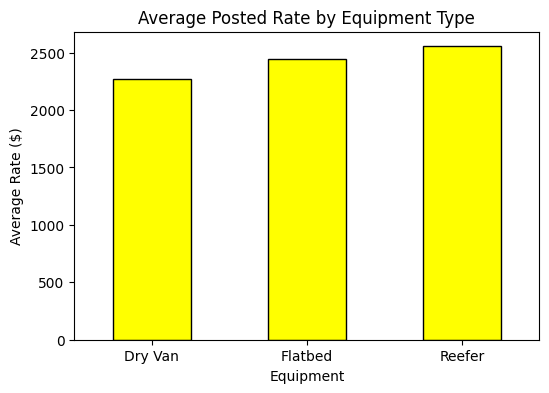

In [31]:
# Equipment vs Average Posted Rate
plt.figure(figsize=(6, 4))
freight.groupby("equipment")["posted_rate"].mean().plot(kind="bar", color="yellow", edgecolor="black")
plt.title("Average Posted Rate by Equipment Type")
plt.xlabel("Equipment")
plt.ylabel("Average Rate ($)")
plt.xticks(rotation=0)
plt.show()


In [32]:
#checking the date range in train and validation
print(" Train-test date range:\n" , freight['date'].min() , "to" , freight['date'].max())
print("")
print(" Validation date range:\n" , valide['date'].min(), "to" , valide['date'].max())

 Train-test date range:
 2025-01-01 to 2025-10-31

 Validation date range:
 2025-11-01 to 2025-12-31


## Feature Engineering

In [33]:
# with the help of date coulmn creating 2 features: month and day_of_week 
# month tells the Annual Seasonality like(Holiday Rush vs slump) (month 1 to 12)
# day_of_week tells weekly urgency and carrier supply (0=Monday to 6=Sunday)
# in both dataset need to create the futures so model can make predictions on validation.csv 

print(freight['date'].dtypes) #checkig the datatype

for data in [freight , valide]:
    data['date'] = pd.to_datetime(data['date'])
    data['month'] = data['date'].dt.month
    data['day_of_week'] = data['date'].dt.dayofweek

print(freight.columns)
print("")
print(valide.columns)

object
Index(['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon',
       'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight',
       'date', 'market_index', 'quote_signal', 'posted_rate', 'month',
       'day_of_week'],
      dtype='object')

Index(['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon',
       'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight',
       'date', 'market_index', 'quote_signal', 'month', 'day_of_week'],
      dtype='object')


In [34]:
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,month,day_of_week
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,1,2
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,1,2
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,1,2
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,1,2
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,1,2


In [35]:
valide.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,month,day_of_week
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388,11,5
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240,11,5
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480,11,5
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579,11,5
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,31496.0,2025-11-01,0.88308,2.22541,11,5


In [36]:
# if model can see the pattrens like trip cost and market tightness 
#creating 3 freight domains called "est_cost" , "market_pressure" , "is_short_haul"

for data in [freight , valide]:
    # est_cost 
    data['est_cost'] = data['distance'] * data['quote_signal']
    # market_pressure
    data['market_presssure'] = data['market_index'] * data['quote_signal']
    # is_short_haul
    data['is_short_haul'] = (data['distance'] < 250).astype(int)

print(freight.columns)
print("")
print(valide.columns)

Index(['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon',
       'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight',
       'date', 'market_index', 'quote_signal', 'posted_rate', 'month',
       'day_of_week', 'est_cost', 'market_presssure', 'is_short_haul'],
      dtype='object')

Index(['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon',
       'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight',
       'date', 'market_index', 'quote_signal', 'month', 'day_of_week',
       'est_cost', 'market_presssure', 'is_short_haul'],
      dtype='object')


In [37]:
#encoding the "equipment"
#using pd.get_dummies its flags the euipmentts in Yes/No 
from numpy import dtype
from numpy import column_stack
freight = pd.get_dummies(freight, columns=['equipment'] , drop_first=True , dtype=int)
valide = pd.get_dummies(valide , columns=['equipment'] , drop_first=True , dtype=int)

In [38]:
# check for encoded columns in both train-test and validation dataset
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate,month,day_of_week,est_cost,market_presssure,is_short_haul,equipment_Flatbed,equipment_Reefer
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,30658.0,2025-01-01,0.95684,2.39595,645.41,1,2,657.209085,2.292541,0,0,0
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,17555.0,2025-01-01,0.97623,2.43355,679.97,1,2,682.610775,2.375705,0,0,1
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,31721.0,2025-01-01,1.00971,1.84491,1802.54,1,2,1785.503898,1.862824,0,0,0
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,32333.0,2025-01-01,0.94518,1.87712,1827.28,1,2,1812.171648,1.774216,0,0,0
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,35183.0,2025-01-01,0.98480,2.56300,1380.28,1,2,1388.889700,2.524042,0,0,1


## Train and  Validation

In [39]:
# first creating boolean values for both traain and validation (time based split)
# Jan to Aug for traning (8 months) and Sep to Oct for validation(2 months)

train_data = freight['date'] < '2025-09-01' # takes  before (jan 1 to aug 31)
val_data = freight['date'] >= '2025-09-01' # takes after (sep 1 to cot 31)

In [40]:
# droping the coulmns from futures such as load_id , date , posted rate(target) , and pickup , devlivery 
# reason for droping "pickup" , "devlivery" column
# Both columns contain over 64 unique city text names. One hot encoding them would create thousands of separte columns,
# leading to high dimensionality, memory bloat, and severe model overfitting. 
# The Spatial coordinates (lat/long) and haul distance already provide the full geographic routing signal cleanly.

drop_cols = ['load_id', 'date', 'posted_rate' , 'pickup' , 'delivery']

#separating futures and target for train
X_train = freight[train_data].drop(columns=drop_cols , errors='ignore')
y_train = freight[train_data]['posted_rate']

# same as for validation
X_val = freight[val_data].drop(columns=drop_cols , errors='ignore')
y_val = freight[val_data]['posted_rate']

#cheking its shape to conforming splits 
print("X_train shape:" , X_train.shape)
print("x_val shape:" ,X_val.shape )
print("\n Futures used:\n" , X_train.columns.tolist())

X_train shape: (38477, 15)
x_val shape: (9523, 15)

 Futures used:
 ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'month', 'day_of_week', 'est_cost', 'market_presssure', 'is_short_haul', 'equipment_Flatbed', 'equipment_Reefer']


In [41]:
# Installing LightGBM gradient boosting library
%pip install Lightgbm

Note: you may need to restart the kernel to use updated packages.


In [42]:
# Installing scikit-learn library for evaluation metrics
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [43]:
# training the LightGBM model becouse,
# Non linearity in freight rates exibits non linear economies of scale (haul decay) that linear model fail to capture 
# and LightGBM does not need scaling

import lightgbm as lgb
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

model = lgb.LGBMRegressor(n_estimators=500 , learning_rate = 0.05 , random_state = 42)

# fit on traning data
model.fit(X_train , y_train)

#prediction on validation data
val_pred = model.predict(X_val)

# metrics
mae = mean_absolute_error(y_val , val_pred)
rmse = np.sqrt(mean_squared_error(y_val , val_pred))
r2_score = r2_score(y_val  , val_pred) 

print("LightGBM Validation Results:")
print(f"MAE:   ${mae:.2f}")
print(f"RMSE:  ${rmse:.2f}")
print(f"R^2:   {r2_score:.4f}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004282 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1810
[LightGBM] [Info] Number of data points in the train set: 38477, number of used features: 15
[LightGBM] [Info] Start training from score 2369.409512
LightGBM Validation Results:
MAE:   $149.99
RMSE:  $646.16
R^2:   0.8207


<Figure size 1000x600 with 0 Axes>

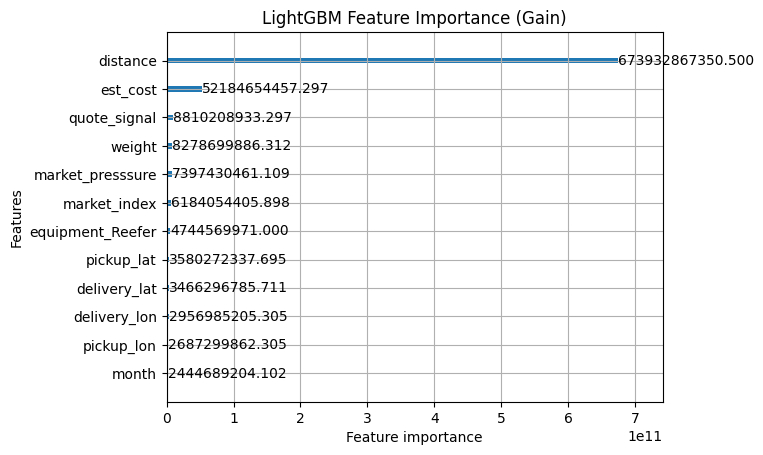

In [44]:
#cheking what futures model learned mostly
plt.figure(figsize=(10,6))
lgb.plot_importance(model, max_num_features=12, importance_type='gain')
plt.title("LightGBM Feature Importance (Gain)")
plt.show()

In [45]:
#Hyperparameter Tuning optimising LightGBM to reduce the doller error(MAE)
from sklearn.metrics import r2_score
tuned_model = lgb.LGBMRegressor(n_estimators=700, learning_rate=0.03,num_leaves=63, objective='regression_l1', random_state=42)

# fit the model again on traning data
tuned_model.fit(X_train , y_train)

#predicting on the validation data
tuned_preds = tuned_model.predict(X_val)

#check metrics
tuned_mae = mean_absolute_error(y_val , tuned_preds)
tuned_r2 = r2_score(y_val , tuned_preds)

print("Tuned lightGBM Results:")
print(f"MAE: ${tuned_mae:.2f}")
print(f"R^2: {tuned_r2:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001712 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1810
[LightGBM] [Info] Number of data points in the train set: 38477, number of used features: 15
[LightGBM] [Info] Start training from score 2026.040039
Tuned lightGBM Results:
MAE: $114.36
R^2: 0.8264


In [46]:
# Genrating Validation_prediction.csv file 

# matching exact futures used by model
feature_cols = X_train.columns.to_list()
x_test_final = valide[feature_cols]

#predict rate on tuned model
final_pred = tuned_model.predict(x_test_final)

# Creating submission dataframe matching required template
submission = pd.DataFrame({'load_id': valide['load_id'],'predicted_rate': final_pred})

# save to root directory
submission.to_csv("validation_predictions.csv" , index=False)

print("saved validation_prediction.csv file")
print("Rows count:" , len(submission))
print(submission.head())


saved validation_prediction.csv file
Rows count: 12000
     load_id  predicted_rate
0  TE-000001      832.226666
1  TE-000002     4841.079243
2  TE-000003     5105.363421
3  TE-000004     4100.337118
4  TE-000005     1818.170826


In [47]:
# predicting on December Chart inputs 31 days

#  Loading the December template
dec_data = pd.read_csv(r"C:\Users\Ravichandran\OneDrive\Desktop\freight-rate-ml\data\december-chart-inputs.csv")
dec_data['date'] = pd.to_datetime(dec_data['date'])

#  Get Lexington and Fort Wayne coordinates from training data
lex_coords = freight[freight['pickup'] == 'Lexington'][['pickup_lat', 'pickup_lon']].iloc[0]
fw_coords = freight[freight['delivery'] == 'Fort Wayne'][['delivery_lat', 'delivery_lon']].iloc[0]

#  Get daily December market_index & quote_signal from valide data
valide['date_dt'] = pd.to_datetime(valide['date'])
daily_market = valide.groupby('date_dt')[['market_index', 'quote_signal']].mean()

# Fallback values if some of the days had no trucks
dec_market_median = valide['market_index'].median()
dec_quote_median = valide['quote_signal'].median()

# 4. Building feature table for December
X_dec = pd.DataFrame()
X_dec['pickup_lat'] = [lex_coords['pickup_lat']] * len(dec_data)
X_dec['pickup_lon'] = [lex_coords['pickup_lon']] * len(dec_data)
X_dec['delivery_lat'] = [fw_coords['delivery_lat']] * len(dec_data)
X_dec['delivery_lon'] = [fw_coords['delivery_lon']] * len(dec_data)
X_dec['distance'] = dec_data['distance']
X_dec['weight'] = dec_data['weight']

# Maping  daily market_index and quote_signal by date
X_dec['market_index'] = dec_data['date'].map(daily_market['market_index']).fillna(dec_market_median)
X_dec['quote_signal'] = dec_data['date'].map(daily_market['quote_signal']).fillna(dec_quote_median)

# Date features
X_dec['month'] = dec_data['date'].dt.month
X_dec['day_of_week'] = dec_data['date'].dt.dayofweek

# Domain interaction features
X_dec['est_cost'] = X_dec['distance'] * X_dec['quote_signal']
X_dec['market_presssure'] = X_dec['market_index'] * X_dec['quote_signal']
X_dec['is_short_haul'] = (X_dec['distance'] < 250).astype(int)

# Equipment (It is Dry Van, so Flatbed=0 and Reefer=0)
X_dec['equipment_Flatbed'] = 0
X_dec['equipment_Reefer'] = 0

#  make predictions
dec_preds = tuned_model.predict(X_dec[feature_cols])

#  Filling predicted_rate and save
dec_data['predicted_rate'] = dec_preds
dec_data['date'] = dec_data['date'].dt.strftime('%Y-%m-%d')

# Save to data directory
dec_data.to_csv(r"C:\Users\Ravichandran\OneDrive\Desktop\freight-rate-ml\data\december-chart-inputs.csv", index=False)

print("Saved December predictions successfully!")
print(dec_data.head())


Saved December predictions successfully!
      pickup    delivery  distance equipment  weight        date  \
0  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-01   
1  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-02   
2  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-03   
3  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-04   
4  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-05   

   predicted_rate  
0      806.949480  
1      813.258659  
2      824.583811  
3      828.558818  
4      819.513779  


In [48]:
import joblib

joblib.dump(tuned_model, 'freight_rate_model.joblib')
print(" Model successfully saved ")


 Model successfully saved 
